# Vision Mamba + InceptionV3 + Swin Transformer — Attention-Based Adaptive Fusion Ensemble

This notebook loads the three trained checkpoints and performs **attention-based adaptive fusion**. The three base networks are frozen; a small gating/attention network learns sample-specific weights from their 5-class probability outputs using the validation set, then evaluates on the untouched test set.


In [3]:
# ================================================================
# 0. Google Drive + common imports
# ================================================================
from google.colab import drive
drive.mount("/content/drive")

import os, glob, random, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Mounted at /content/drive
Device: cuda
GPU: Tesla T4


## 1. Vision Mamba environment

The following is the corrected installation cell from the uploaded Vision Mamba notebook. It is retained because the Vim architecture requires the compiled Mamba CUDA extension.

In [5]:
import os
import sys
import time
import inspect
import subprocess
import shutil
import importlib
import torch

assert torch.cuda.is_available(), (
    "GPU is not available. "
    "Go to Runtime > Change runtime type > T4 GPU."
)

GPU_NAME = torch.cuda.get_device_name(0)
CC = torch.cuda.get_device_capability(0)
CUDA_ARCH = f"{CC[0]}{CC[1]}"

print("=" * 70)
print("GPU INFORMATION")
print("=" * 70)
print("GPU:", GPU_NAME)
print("CUDA compute capability:", CC)
print("Architecture:", f"sm_{CUDA_ARCH}")
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)


# ================================================================
# 2. SHELL HELPER
# ================================================================

def sh(cmd, env=None):
    print("\n$ " + cmd)

    result = subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        env=env,
        capture_output=True,
        text=True
    )

    output = result.stdout + "\n" + result.stderr

    if result.returncode != 0:
        print("\n" + "=" * 70)
        print("COMMAND FAILED")
        print("=" * 70)
        print(output[-30000:])
        raise RuntimeError(
            f"Command failed:\n{cmd}"
        )

    if result.stdout:
        print(result.stdout[-8000:])

    return result.stdout


# ================================================================
# 3. REMOVE OLD INSTALLATION
# ================================================================

VIM = "/content/Vim"

print("\n" + "=" * 70)
print("CLEANING OLD INSTALLATION")
print("=" * 70)

if os.path.isdir(VIM):
    print("Removing:", VIM)
    shutil.rmtree(VIM)

sh(
    "pip uninstall -y mamba-ssm causal-conv1d "
    "2>/dev/null || true"
)


# ================================================================
# 4. INSTALL BUILD DEPENDENCIES
# ================================================================

print("\n" + "=" * 70)
print("INSTALLING DEPENDENCIES")
print("=" * 70)

sh(
    "pip install -q "
    "einops "
    "ninja "
    "packaging "
    "timm "
    "huggingface_hub "
    "transformers "
    "triton"
)


# ================================================================
# 5. CLONE FRESH VIM
# ================================================================

print("\n" + "=" * 70)
print("CLONING VIM")
print("=" * 70)

sh(
    f"git clone -q --depth 1 "
    f"https://github.com/hustvl/Vim.git "
    f"{VIM}"
)


# ================================================================
# 6. RESET SETUP FILES
# ================================================================

MAMBA_SETUP = (
    f"{VIM}/mamba-1p1p1/setup.py"
)

CAUSAL_SETUP = (
    f"{VIM}/causal-conv1d/setup.py"
)

print("\nResetting setup.py files...")

sh(
    f"cd {VIM}/mamba-1p1p1 && "
    "git checkout -- setup.py"
)

sh(
    f"cd {VIM}/causal-conv1d && "
    "git checkout -- setup.py"
)


# ================================================================
# 7. PATCH CUDA ARCHITECTURE
# ================================================================

def patch_cuda_arch(setup_path):

    text = open(
        setup_path,
        "r",
        encoding="utf-8"
    ).read()

    if "VIM_CUDA_ARCH" in text:
        print(
            "CUDA architecture already patched:",
            setup_path
        )
        return

    anchor = (
        "    # HACK: The compiler flag "
        "-D_GLIBCXX_USE_CXX11_ABI"
    )

    if anchor not in text:
        raise RuntimeError(
            "CUDA patch anchor not found in:\n"
            + setup_path
        )

    patch = (
        '    _vim_arch = os.getenv("VIM_CUDA_ARCH")\n'
        '    if _vim_arch and not HIP_BUILD:\n'
        '        cc_flag = [\n'
        '            "-gencode",\n'
        '            f"arch=compute_{_vim_arch},'
        'code=sm_{_vim_arch}"\n'
        '        ]\n\n'
        + anchor
    )

    text = text.replace(
        anchor,
        patch,
        1
    )

    with open(
        setup_path,
        "w",
        encoding="utf-8"
    ) as f:
        f.write(text)

    print(
        "Patched CUDA architecture:",
        setup_path
    )


patch_cuda_arch(MAMBA_SETUP)
patch_cuda_arch(CAUSAL_SETUP)
REVERSE_SCAN = (
    f"{VIM}/mamba-1p1p1/"
    "csrc/selective_scan/reverse_scan.cuh"
)

print("\n" + "=" * 70)
print("PATCHING CUDA 13 CUB COMPATIBILITY")
print("=" * 70)
reverse = open(
    REVERSE_SCAN,
    "r",
    encoding="utf-8"
).read()
lane_count = reverse.count(
    "cub::LaneId()"
)
cta_count = reverse.count(
    "cub::CTA_SYNC()"
)
print(
    "Found cub::LaneId():",
    lane_count
)
print(
    "Found cub::CTA_SYNC():",
    cta_count
)
reverse = reverse.replace(
    "cub::LaneId()",
    "__vim_lane_id()"
)


# ------------------------------------------------
# Replace CTA synchronization
# ------------------------------------------------

reverse = reverse.replace(
    "cub::CTA_SYNC()",
    "__syncthreads()"
)


# ------------------------------------------------
# Add compatibility helper near top of file
# ------------------------------------------------

if "__vim_lane_id()" in reverse:

    helper = r'''
// ================================================================
// CUDA 13 compatibility:
//
// Older CUB versions exposed cub::LaneId().
// CUDA 13 no longer exposes that old helper.
//
// Read the PTX %laneid register directly.
// ================================================================

#ifndef VIM_CUDA13_COMPAT_LANE_ID
#define VIM_CUDA13_COMPAT_LANE_ID

__device__ __forceinline__
unsigned int __vim_lane_id() {
    unsigned int lane;
    asm volatile(
        "mov.u32 %0, %%laneid;"
        : "=r"(lane)
    );
    return lane;
}

#endif

'''

    marker = "#pragma once"

    if "__vim_lane_id()" not in reverse.split(
        marker,
        1
    )[0]:

        reverse = reverse.replace(
            marker,
            marker + "\n" + helper,
            1
        )


with open(
    REVERSE_SCAN,
    "w",
    encoding="utf-8"
) as f:
    f.write(reverse)


print("\nCUDA 13 compatibility patch applied.")

print(
    "Remaining cub::LaneId():",
    reverse.count("cub::LaneId()")
)

print(
    "Remaining cub::CTA_SYNC():",
    reverse.count("cub::CTA_SYNC()")
)


# ================================================================
# 9. TRANSFORMERS COMPATIBILITY
# ================================================================

GENERATION = (
    f"{VIM}/mamba-1p1p1/"
    "mamba_ssm/utils/generation.py"
)

print("\nChecking Transformers compatibility...")

g = open(
    GENERATION,
    "r",
    encoding="utf-8"
).read()

old_import = (
    "from transformers.generation import "
    "GreedySearchDecoderOnlyOutput, "
    "SampleDecoderOnlyOutput, TextStreamer"
)

if old_import in g:

    new_import = """try:
    from transformers.generation import (
        GreedySearchDecoderOnlyOutput,
        SampleDecoderOnlyOutput,
        TextStreamer,
    )
except ImportError:
    from transformers.generation import (
        GenerateDecoderOnlyOutput as GreedySearchDecoderOnlyOutput,
        GenerateDecoderOnlyOutput as SampleDecoderOnlyOutput,
        TextStreamer,
    )
"""

    g = g.replace(
        old_import,
        new_import,
        1
    )

    with open(
        GENERATION,
        "w",
        encoding="utf-8"
    ) as f:
        f.write(g)

    print(
        "Transformers compatibility patch applied."
    )

else:
    print(
        "Transformers compatibility patch not required."
    )


# ================================================================
# 10. IMPORTANT:
# DO NOT MODIFY selective_scan_interface.py
# ================================================================

print(
    "\nLeaving selective_scan_interface.py unchanged."
)

print(
    "selective_scan_cuda will be compiled normally."
)


# ================================================================
# 11. BUILD ENVIRONMENT
# ================================================================

env = dict(
    os.environ,

    VIM_CUDA_ARCH=CUDA_ARCH,

    MAMBA_FORCE_BUILD="TRUE",

    CAUSAL_CONV1D_FORCE_BUILD="TRUE",

    MAX_JOBS=str(
        max(
            1,
            min(
                2,
                os.cpu_count() or 2
            )
        )
    )
)

print("\n" + "=" * 70)
print("BUILD CONFIGURATION")
print("=" * 70)

print(
    "GPU:",
    GPU_NAME
)

print(
    "CUDA:",
    torch.version.cuda
)

print(
    "Architecture:",
    f"sm_{CUDA_ARCH}"
)

print(
    "MAX_JOBS:",
    env["MAX_JOBS"]
)


# ================================================================
# 12. BUILD causal-conv1d
# ================================================================

t0 = time.time()

print("\n" + "=" * 70)
print("BUILDING causal-conv1d")
print("=" * 70)

sh(
    f"cd {VIM}/causal-conv1d && "
    "pip install "
    "--verbose "
    "--no-build-isolation "
    "--no-deps "
    ".",
    env
)

print(
    "\ncausal-conv1d build time:",
    f"{(time.time() - t0) / 60:.2f} minutes"
)


# ================================================================
# 13. TEST causal-conv1d
# ================================================================

print("\nTesting causal_conv1d...")

import causal_conv1d

print(
    "causal_conv1d:",
    causal_conv1d.__file__
)

try:
    import causal_conv1d_cuda

    print(
        "causal_conv1d_cuda:",
        causal_conv1d_cuda.__file__
    )

except Exception:
    import traceback
    traceback.print_exc()
    raise


# ================================================================
# 14. BUILD mamba_ssm
#
# IMPORTANT:
#
# We DO NOT do:
#
#     ext_modules=[]
#
# because that would remove selective_scan_cuda.
# ================================================================

print("\n" + "=" * 70)
print("BUILDING mamba_ssm + selective_scan_cuda")
print("=" * 70)

sh(
    f"cd {VIM}/mamba-1p1p1 && "
    "pip install "
    "--verbose "
    "--no-build-isolation "
    "--no-deps "
    ".",
    env
)

print(
    "\nMamba build time:",
    f"{(time.time() - t0) / 60:.2f} minutes"
)


# ================================================================
# 15. CLEAR PYTHON CACHE
# ================================================================

for key in list(
    sys.modules.keys()
):

    if (
        "mamba_ssm" in key
        or "causal_conv1d" in key
        or "selective_scan_cuda" in key
    ):
        sys.modules.pop(
            key,
            None
        )

importlib.invalidate_caches()


# ================================================================
# 16. VERIFY selective_scan_cuda
# ================================================================

print("\n" + "=" * 70)
print("VERIFYING selective_scan_cuda")
print("=" * 70)

try:

    import selective_scan_cuda

    print(
        "SUCCESS: selective_scan_cuda imported."
    )

    print(
        "Location:",
        selective_scan_cuda.__file__
    )

except Exception:

    import traceback
    traceback.print_exc()

    raise RuntimeError(
        "selective_scan_cuda could not be imported."
    )


# ================================================================
# 17. VERIFY mamba_ssm
# ================================================================

print("\n" + "=" * 70)
print("VERIFYING mamba_ssm")
print("=" * 70)

try:

    import mamba_ssm

    from mamba_ssm.modules.mamba_simple import Mamba

    print(
        "SUCCESS: mamba_ssm imported."
    )

    print(
        "Location:",
        mamba_ssm.__file__
    )

except Exception:

    import traceback
    traceback.print_exc()

    raise


# ================================================================
# 18. VERIFY Vim-specific API
# ================================================================

print("\n" + "=" * 70)
print("VERIFYING Vim Mamba API")
print("=" * 70)

signature = inspect.signature(
    Mamba.__init__
)

parameters = list(
    signature.parameters.keys()
)

print(
    "Mamba parameters:"
)

print(
    parameters
)

if "bimamba_type" not in parameters:

    raise RuntimeError(
        "Vim-compatible Mamba was not installed. "
        "'bimamba_type' is missing."
    )

print(
    "\nSUCCESS: bimamba_type is available."
)


# ================================================================
# 19. FINAL
# ================================================================

print("\n" + "=" * 70)
print("VIM KERNELS READY")
print("=" * 70)

print(
    "GPU                  :",
    GPU_NAME
)

print(
    "CUDA architecture    :",
    f"sm_{CUDA_ARCH}"
)

print(
    "PyTorch CUDA         :",
    torch.version.cuda
)

print(
    "causal_conv1d        : OK"
)

print(
    "causal_conv1d_cuda   : OK"
)

print(
    "selective_scan_cuda  : OK"
)

print(
    "mamba_ssm            : OK"
)

print(
    "bimamba_type         : OK"
)

print(
    "\nVision Mamba dependencies are ready."
)

GPU INFORMATION
GPU: Tesla T4
CUDA compute capability: (7, 5)
Architecture: sm_75
PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0

CLEANING OLD INSTALLATION
Removing: /content/Vim

$ pip uninstall -y mamba-ssm causal-conv1d 2>/dev/null || true
Found existing installation: causal_conv1d 1.4.0
Uninstalling causal_conv1d-1.4.0:
  Successfully uninstalled causal_conv1d-1.4.0


INSTALLING DEPENDENCIES

$ pip install -q einops ninja packaging timm huggingface_hub transformers triton

CLONING VIM

$ git clone -q --depth 1 https://github.com/hustvl/Vim.git /content/Vim

Resetting setup.py files...

$ cd /content/Vim/mamba-1p1p1 && git checkout -- setup.py

$ cd /content/Vim/causal-conv1d && git checkout -- setup.py
Patched CUDA architecture: /content/Vim/mamba-1p1p1/setup.py
Patched CUDA architecture: /content/Vim/causal-conv1d/setup.py

PATCHING CUDA 13 CUB COMPATIBILITY
Found cub::LaneId(): 1
Found cub::CTA_SYNC(): 3

CUDA 13 compatibility patch applied.
Remaining cub::LaneId(): 1
Remaining cub::CT

/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:163: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:232: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:300: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.13/dist-packages/mamba_ssm/ops/selective_scan_interface.py:376: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.13/dist-packages/

SUCCESS: mamba_ssm imported.
Location: /usr/local/lib/python3.13/dist-packages/mamba_ssm/__init__.py

VERIFYING Vim Mamba API
Mamba parameters:
['self', 'd_model', 'd_state', 'd_conv', 'expand', 'dt_rank', 'dt_min', 'dt_max', 'dt_init', 'dt_scale', 'dt_init_floor', 'conv_bias', 'bias', 'use_fast_path', 'layer_idx', 'device', 'dtype', 'bimamba_type', 'if_divide_out', 'init_layer_scale']

SUCCESS: bimamba_type is available.

VIM KERNELS READY
GPU                  : Tesla T4
CUDA architecture    : sm_75
PyTorch CUDA         : 13.0
causal_conv1d        : OK
causal_conv1d_cuda   : OK
selective_scan_cuda  : OK
mamba_ssm            : OK
bimamba_type         : OK

Vision Mamba dependencies are ready.


## 2. Vision Mamba architecture

This is the architecture from the uploaded `vision_mambacorrected.ipynb`; it is kept unchanged so the checkpoint matches the model definition.

In [6]:
# ===== Vision Mamba (Vim) architecture: copied UNCHANGED from vim/models_mamba.py =====
import sys
sys.path.insert(0, "/content/Vim/vim")   # only addition: so that `from rope import *` finds rope.py

# Copyright (c) 2015-present, Facebook, Inc.
# All rights reserved.
import torch
import torch.nn as nn
from functools import partial
from torch import Tensor
from typing import Optional

from timm.models.vision_transformer import VisionTransformer, _cfg
from timm.models.registry import register_model
from timm.models.layers import trunc_normal_, lecun_normal_

from timm.models.layers import DropPath, to_2tuple
from timm.models.vision_transformer import _load_weights

import math

from collections import namedtuple

from mamba_ssm.modules.mamba_simple import Mamba
from mamba_ssm.utils.generation import GenerationMixin
from mamba_ssm.utils.hf import load_config_hf, load_state_dict_hf

from rope import *
import random

try:
    from mamba_ssm.ops.triton.layer_norm import RMSNorm, layer_norm_fn, rms_norm_fn
except ImportError:
    RMSNorm, layer_norm_fn, rms_norm_fn = None, None, None


__all__ = [
    'vim_tiny_patch16_224', 'vim_small_patch16_224', 'vim_base_patch16_224',
    'vim_tiny_patch16_384', 'vim_small_patch16_384', 'vim_base_patch16_384',
]


class PatchEmbed(nn.Module):
    """ 2D Image to Patch Embedding
    """
    def __init__(self, img_size=224, patch_size=16, stride=16, in_chans=3, embed_dim=768, norm_layer=None, flatten=True):
        super().__init__()
        img_size = to_2tuple(img_size)
        patch_size = to_2tuple(patch_size)
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = ((img_size[0] - patch_size[0]) // stride + 1, (img_size[1] - patch_size[1]) // stride + 1)
        self.num_patches = self.grid_size[0] * self.grid_size[1]
        self.flatten = flatten

        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=stride)
        self.norm = norm_layer(embed_dim) if norm_layer else nn.Identity()

    def forward(self, x):
        B, C, H, W = x.shape
        assert H == self.img_size[0] and W == self.img_size[1], \
            f"Input image size ({H}*{W}) doesn't match model ({self.img_size[0]}*{self.img_size[1]})."
        x = self.proj(x)
        if self.flatten:
            x = x.flatten(2).transpose(1, 2)  # BCHW -> BNC
        x = self.norm(x)
        return x


class Block(nn.Module):
    def __init__(
        self, dim, mixer_cls, norm_cls=nn.LayerNorm, fused_add_norm=False, residual_in_fp32=False,drop_path=0.,
    ):
        """
        Simple block wrapping a mixer class with LayerNorm/RMSNorm and residual connection"

        This Block has a slightly different structure compared to a regular
        prenorm Transformer block.
        The standard block is: LN -> MHA/MLP -> Add.
        [Ref: https://arxiv.org/abs/2002.04745]
        Here we have: Add -> LN -> Mixer, returning both
        the hidden_states (output of the mixer) and the residual.
        This is purely for performance reasons, as we can fuse add and LayerNorm.
        The residual needs to be provided (except for the very first block).
        """
        super().__init__()
        self.residual_in_fp32 = residual_in_fp32
        self.fused_add_norm = fused_add_norm
        # import ipdb; ipdb.set_trace()
        self.mixer = mixer_cls(dim)
        self.norm = norm_cls(dim)
        self.drop_path = DropPath(drop_path) if drop_path > 0. else nn.Identity()
        if self.fused_add_norm:
            assert RMSNorm is not None, "RMSNorm import fails"
            assert isinstance(
                self.norm, (nn.LayerNorm, RMSNorm)
            ), "Only LayerNorm and RMSNorm are supported for fused_add_norm"

    def forward(
        self, hidden_states: Tensor, residual: Optional[Tensor] = None, inference_params=None
    ):
        r"""Pass the input through the encoder layer.

        Args:
            hidden_states: the sequence to the encoder layer (required).
            residual: hidden_states = Mixer(LN(residual))
        """
        if not self.fused_add_norm:
            if residual is None:
                residual = hidden_states
            else:
                residual = residual + self.drop_path(hidden_states)

            hidden_states = self.norm(residual.to(dtype=self.norm.weight.dtype))
            if self.residual_in_fp32:
                residual = residual.to(torch.float32)
        else:
            fused_add_norm_fn = rms_norm_fn if isinstance(self.norm, RMSNorm) else layer_norm_fn
            if residual is None:
                hidden_states, residual = fused_add_norm_fn(
                    hidden_states,
                    self.norm.weight,
                    self.norm.bias,
                    residual=residual,
                    prenorm=True,
                    residual_in_fp32=self.residual_in_fp32,
                    eps=self.norm.eps,
                )
            else:
                hidden_states, residual = fused_add_norm_fn(
                    self.drop_path(hidden_states),
                    self.norm.weight,
                    self.norm.bias,
                    residual=residual,
                    prenorm=True,
                    residual_in_fp32=self.residual_in_fp32,
                    eps=self.norm.eps,
                )
        hidden_states = self.mixer(hidden_states, inference_params=inference_params)
        return hidden_states, residual

    def allocate_inference_cache(self, batch_size, max_seqlen, dtype=None, **kwargs):
        return self.mixer.allocate_inference_cache(batch_size, max_seqlen, dtype=dtype, **kwargs)


def create_block(
    d_model,
    d_state=16,
    ssm_cfg=None,
    norm_epsilon=1e-5,
    drop_path=0.,
    rms_norm=False,
    residual_in_fp32=False,
    fused_add_norm=False,
    layer_idx=None,
    device=None,
    dtype=None,
    if_bimamba=False,
    bimamba_type="none",
    if_divide_out=False,
    init_layer_scale=None,
):
    if if_bimamba:
        bimamba_type = "v1"
    if ssm_cfg is None:
        ssm_cfg = {}
    factory_kwargs = {"device": device, "dtype": dtype}
    # import ipdb; ipdb.set_trace()
    mixer_cls = partial(Mamba, d_state=d_state, layer_idx=layer_idx, bimamba_type=bimamba_type, if_divide_out=if_divide_out, init_layer_scale=init_layer_scale, **ssm_cfg, **factory_kwargs)
    norm_cls = partial(
        nn.LayerNorm if not rms_norm else RMSNorm, eps=norm_epsilon, **factory_kwargs
    )
    block = Block(
        d_model,
        mixer_cls,
        norm_cls=norm_cls,
        drop_path=drop_path,
        fused_add_norm=fused_add_norm,
        residual_in_fp32=residual_in_fp32,
    )
    block.layer_idx = layer_idx
    return block


# https://github.com/huggingface/transformers/blob/c28d04e9e252a1a099944e325685f14d242ecdcd/src/transformers/models/gpt2/modeling_gpt2.py#L454
def _init_weights(
    module,
    n_layer,
    initializer_range=0.02,  # Now only used for embedding layer.
    rescale_prenorm_residual=True,
    n_residuals_per_layer=1,  # Change to 2 if we have MLP
):
    if isinstance(module, nn.Linear):
        if module.bias is not None:
            if not getattr(module.bias, "_no_reinit", False):
                nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Embedding):
        nn.init.normal_(module.weight, std=initializer_range)

    if rescale_prenorm_residual:
        # Reinitialize selected weights subject to the OpenAI GPT-2 Paper Scheme:
        #   > A modified initialization which accounts for the accumulation on the residual path with model depth. Scale
        #   > the weights of residual layers at initialization by a factor of 1/√N where N is the # of residual layers.
        #   >   -- GPT-2 :: https://openai.com/blog/better-language-models/
        #
        # Reference (Megatron-LM): https://github.com/NVIDIA/Megatron-LM/blob/main/megatron/model/gpt_model.py
        for name, p in module.named_parameters():
            if name in ["out_proj.weight", "fc2.weight"]:
                # Special Scaled Initialization --> There are 2 Layer Norms per Transformer Block
                # Following Pytorch init, except scale by 1/sqrt(2 * n_layer)
                # We need to reinit p since this code could be called multiple times
                # Having just p *= scale would repeatedly scale it down
                nn.init.kaiming_uniform_(p, a=math.sqrt(5))
                with torch.no_grad():
                    p /= math.sqrt(n_residuals_per_layer * n_layer)


def segm_init_weights(m):
    if isinstance(m, nn.Linear):
        trunc_normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.constant_(m.bias, 0)
    elif isinstance(m, nn.Conv2d):
        # NOTE conv was left to pytorch default in my original init
        lecun_normal_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.LayerNorm, nn.GroupNorm, nn.BatchNorm2d)):
        nn.init.zeros_(m.bias)
        nn.init.ones_(m.weight)


class VisionMamba(nn.Module):
    def __init__(self,
                 img_size=224,
                 patch_size=16,
                 stride=16,
                 depth=24,
                 embed_dim=192,
                 d_state=16,
                 channels=3,
                 num_classes=1000,
                 ssm_cfg=None,
                 drop_rate=0.,
                 drop_path_rate=0.1,
                 norm_epsilon: float = 1e-5,
                 rms_norm: bool = True,
                 initializer_cfg=None,
                 fused_add_norm=True,
                 residual_in_fp32=True,
                 device=None,
                 dtype=None,
                 ft_seq_len=None,
                 pt_hw_seq_len=14,
                 if_bidirectional=False,
                 final_pool_type='none',
                 if_abs_pos_embed=True,
                 if_rope=False,
                 if_rope_residual=False,
                 flip_img_sequences_ratio=-1.,
                 if_bimamba=False,
                 bimamba_type="v2",
                 if_cls_token=True,
                 if_divide_out=True,
                 init_layer_scale=None,
                 use_double_cls_token=False,
                 use_middle_cls_token=True,
                 **kwargs):
        factory_kwargs = {"device": device, "dtype": dtype}
        # add factory_kwargs into kwargs
        kwargs.update(factory_kwargs)
        super().__init__()
        self.residual_in_fp32 = residual_in_fp32
        self.fused_add_norm = fused_add_norm
        self.if_bidirectional = if_bidirectional
        self.final_pool_type = final_pool_type
        self.if_abs_pos_embed = if_abs_pos_embed
        self.if_rope = if_rope
        self.if_rope_residual = if_rope_residual
        self.flip_img_sequences_ratio = flip_img_sequences_ratio
        self.if_cls_token = if_cls_token
        self.use_double_cls_token = use_double_cls_token
        self.use_middle_cls_token = use_middle_cls_token
        self.num_tokens = 1 if if_cls_token else 0

        # pretrain parameters
        self.num_classes = num_classes
        self.d_model = self.num_features = self.embed_dim = embed_dim  # num_features for consistency with other models

        self.patch_embed = PatchEmbed(
            img_size=img_size, patch_size=patch_size, stride=stride, in_chans=channels, embed_dim=embed_dim)
        num_patches = self.patch_embed.num_patches

        if if_cls_token:
            if use_double_cls_token:
                self.cls_token_head = nn.Parameter(torch.zeros(1, 1, self.embed_dim))
                self.cls_token_tail = nn.Parameter(torch.zeros(1, 1, self.embed_dim))
                self.num_tokens = 2
            else:
                self.cls_token = nn.Parameter(torch.zeros(1, 1, self.embed_dim))
                # self.num_tokens = 1

        if if_abs_pos_embed:
            self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + self.num_tokens, self.embed_dim))
            self.pos_drop = nn.Dropout(p=drop_rate)

        if if_rope:
            half_head_dim = embed_dim // 2
            hw_seq_len = img_size // patch_size
            self.rope = VisionRotaryEmbeddingFast(
                dim=half_head_dim,
                pt_seq_len=pt_hw_seq_len,
                ft_seq_len=hw_seq_len
            )
        self.head = nn.Linear(self.num_features, num_classes) if num_classes > 0 else nn.Identity()


        # TODO: release this comment
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, depth)]  # stochastic depth decay rule
        # import ipdb;ipdb.set_trace()
        inter_dpr = [0.0] + dpr
        self.drop_path = DropPath(drop_path_rate) if drop_path_rate > 0. else nn.Identity()
                # transformer blocks
        self.layers = nn.ModuleList(
            [
                create_block(
                    embed_dim,
                    d_state=d_state,
                    ssm_cfg=ssm_cfg,
                    norm_epsilon=norm_epsilon,
                    rms_norm=rms_norm,
                    residual_in_fp32=residual_in_fp32,
                    fused_add_norm=fused_add_norm,
                    layer_idx=i,
                    if_bimamba=if_bimamba,
                    bimamba_type=bimamba_type,
                    drop_path=inter_dpr[i],
                    if_divide_out=if_divide_out,
                    init_layer_scale=init_layer_scale,
                    **factory_kwargs,
                )
                for i in range(depth)
            ]
        )

        # output head
        self.norm_f = (nn.LayerNorm if not rms_norm else RMSNorm)(
            embed_dim, eps=norm_epsilon, **factory_kwargs
        )

        # self.pre_logits = nn.Identity()

        # original init
        self.patch_embed.apply(segm_init_weights)
        self.head.apply(segm_init_weights)
        if if_abs_pos_embed:
            trunc_normal_(self.pos_embed, std=.02)
        if if_cls_token:
            if use_double_cls_token:
                trunc_normal_(self.cls_token_head, std=.02)
                trunc_normal_(self.cls_token_tail, std=.02)
            else:
                trunc_normal_(self.cls_token, std=.02)

        # mamba init
        self.apply(
            partial(
                _init_weights,
                n_layer=depth,
                **(initializer_cfg if initializer_cfg is not None else {}),
            )
        )


    def allocate_inference_cache(self, batch_size, max_seqlen, dtype=None, **kwargs):
        return {
            i: layer.allocate_inference_cache(batch_size, max_seqlen, dtype=dtype, **kwargs)
            for i, layer in enumerate(self.layers)
        }

    @torch.jit.ignore
    def no_weight_decay(self):
        return {"pos_embed", "cls_token", "dist_token", "cls_token_head", "cls_token_tail"}

    @torch.jit.ignore()
    def load_pretrained(self, checkpoint_path, prefix=""):
        _load_weights(self, checkpoint_path, prefix)

    def forward_features(self, x, inference_params=None, if_random_cls_token_position=False, if_random_token_rank=False):
        # taken from https://github.com/rwightman/pytorch-image-models/blob/master/timm/models/vision_transformer.py
        # with slight modifications to add the dist_token
        x = self.patch_embed(x)
        B, M, _ = x.shape

        if self.if_cls_token:
            if self.use_double_cls_token:
                cls_token_head = self.cls_token_head.expand(B, -1, -1)
                cls_token_tail = self.cls_token_tail.expand(B, -1, -1)
                token_position = [0, M + 1]
                x = torch.cat((cls_token_head, x, cls_token_tail), dim=1)
                M = x.shape[1]
            else:
                if self.use_middle_cls_token:
                    cls_token = self.cls_token.expand(B, -1, -1)
                    token_position = M // 2
                    # add cls token in the middle
                    x = torch.cat((x[:, :token_position, :], cls_token, x[:, token_position:, :]), dim=1)
                elif if_random_cls_token_position:
                    cls_token = self.cls_token.expand(B, -1, -1)
                    token_position = random.randint(0, M)
                    x = torch.cat((x[:, :token_position, :], cls_token, x[:, token_position:, :]), dim=1)
                    print("token_position: ", token_position)
                else:
                    cls_token = self.cls_token.expand(B, -1, -1)  # stole cls_tokens impl from Phil Wang, thanks
                    token_position = 0
                    x = torch.cat((cls_token, x), dim=1)
                M = x.shape[1]

        if self.if_abs_pos_embed:
            # if new_grid_size[0] == self.patch_embed.grid_size[0] and new_grid_size[1] == self.patch_embed.grid_size[1]:
            #     x = x + self.pos_embed
            # else:
            #     pos_embed = interpolate_pos_embed_online(
            #                 self.pos_embed, self.patch_embed.grid_size, new_grid_size,0
            #             )
            x = x + self.pos_embed
            x = self.pos_drop(x)

        if if_random_token_rank:

            # 生成随机 shuffle 索引
            shuffle_indices = torch.randperm(M)

            if isinstance(token_position, list):
                print("original value: ", x[0, token_position[0], 0], x[0, token_position[1], 0])
            else:
                print("original value: ", x[0, token_position, 0])
            print("original token_position: ", token_position)

            # 执行 shuffle
            x = x[:, shuffle_indices, :]

            if isinstance(token_position, list):
                # 找到 cls token 在 shuffle 之后的新位置
                new_token_position = [torch.where(shuffle_indices == token_position[i])[0].item() for i in range(len(token_position))]
                token_position = new_token_position
            else:
                # 找到 cls token 在 shuffle 之后的新位置
                token_position = torch.where(shuffle_indices == token_position)[0].item()

            if isinstance(token_position, list):
                print("new value: ", x[0, token_position[0], 0], x[0, token_position[1], 0])
            else:
                print("new value: ", x[0, token_position, 0])
            print("new token_position: ", token_position)




        if_flip_img_sequences = False
        if self.flip_img_sequences_ratio > 0 and (self.flip_img_sequences_ratio - random.random()) > 1e-5:
            x = x.flip([1])
            if_flip_img_sequences = True

        # mamba impl
        residual = None
        hidden_states = x
        if not self.if_bidirectional:
            for layer in self.layers:

                if if_flip_img_sequences and self.if_rope:
                    hidden_states = hidden_states.flip([1])
                    if residual is not None:
                        residual = residual.flip([1])

                # rope about
                if self.if_rope:
                    hidden_states = self.rope(hidden_states)
                    if residual is not None and self.if_rope_residual:
                        residual = self.rope(residual)

                if if_flip_img_sequences and self.if_rope:
                    hidden_states = hidden_states.flip([1])
                    if residual is not None:
                        residual = residual.flip([1])

                hidden_states, residual = layer(
                    hidden_states, residual, inference_params=inference_params
                )
        else:
            # get two layers in a single for-loop
            for i in range(len(self.layers) // 2):
                if self.if_rope:
                    hidden_states = self.rope(hidden_states)
                    if residual is not None and self.if_rope_residual:
                        residual = self.rope(residual)

                hidden_states_f, residual_f = self.layers[i * 2](
                    hidden_states, residual, inference_params=inference_params
                )
                hidden_states_b, residual_b = self.layers[i * 2 + 1](
                    hidden_states.flip([1]), None if residual == None else residual.flip([1]), inference_params=inference_params
                )
                hidden_states = hidden_states_f + hidden_states_b.flip([1])
                residual = residual_f + residual_b.flip([1])

        if not self.fused_add_norm:
            if residual is None:
                residual = hidden_states
            else:
                residual = residual + self.drop_path(hidden_states)
            hidden_states = self.norm_f(residual.to(dtype=self.norm_f.weight.dtype))
        else:
            # Set prenorm=False here since we don't need the residual
            fused_add_norm_fn = rms_norm_fn if isinstance(self.norm_f, RMSNorm) else layer_norm_fn
            hidden_states = fused_add_norm_fn(
                self.drop_path(hidden_states),
                self.norm_f.weight,
                self.norm_f.bias,
                eps=self.norm_f.eps,
                residual=residual,
                prenorm=False,
                residual_in_fp32=self.residual_in_fp32,
            )

        # return only cls token if it exists
        if self.if_cls_token:
            if self.use_double_cls_token:
                return (hidden_states[:, token_position[0], :] + hidden_states[:, token_position[1], :]) / 2
            else:
                if self.use_middle_cls_token:
                    return hidden_states[:, token_position, :]
                elif if_random_cls_token_position:
                    return hidden_states[:, token_position, :]
                else:
                    return hidden_states[:, token_position, :]

        if self.final_pool_type == 'none':
            return hidden_states[:, -1, :]
        elif self.final_pool_type == 'mean':
            return hidden_states.mean(dim=1)
        elif self.final_pool_type == 'max':
            return hidden_states
        elif self.final_pool_type == 'all':
            return hidden_states
        else:
            raise NotImplementedError

    def forward(self, x, return_features=False, inference_params=None, if_random_cls_token_position=False, if_random_token_rank=False):
        x = self.forward_features(x, inference_params, if_random_cls_token_position=if_random_cls_token_position, if_random_token_rank=if_random_token_rank)
        if return_features:
            return x
        x = self.head(x)
        if self.final_pool_type == 'max':
            x = x.max(dim=1)[0]
        return x


@register_model
def vim_tiny_patch16_224_bimambav2_final_pool_mean_abs_pos_embed_with_midclstok_div2(pretrained=False, **kwargs):
    model = VisionMamba(
        patch_size=16, embed_dim=192, depth=24, rms_norm=True, residual_in_fp32=True, fused_add_norm=True, final_pool_type='mean', if_abs_pos_embed=True, if_rope=False, if_rope_residual=False, bimamba_type="v2", if_cls_token=True, if_divide_out=True, use_middle_cls_token=True, **kwargs)
    model.default_cfg = _cfg()
    if pretrained:
        checkpoint = torch.hub.load_state_dict_from_url(
            url="to.do",
            map_location="cpu", check_hash=True
        )
        model.load_state_dict(checkpoint["model"])
    return model

@register_model
def vim_tiny_patch16_stride8_224_bimambav2_final_pool_mean_abs_pos_embed_with_midclstok_div2(pretrained=False, **kwargs):
    model = VisionMamba(
        patch_size=16, stride=8, embed_dim=192, depth=24, rms_norm=True, residual_in_fp32=True, fused_add_norm=True, final_pool_type='mean', if_abs_pos_embed=True, if_rope=False, if_rope_residual=False, bimamba_type="v2", if_cls_token=True, if_divide_out=True, use_middle_cls_token=True, **kwargs)
    model.default_cfg = _cfg()
    if pretrained:
        checkpoint = torch.hub.load_state_dict_from_url(
            url="to.do",
            map_location="cpu", check_hash=True
        )
        model.load_state_dict(checkpoint["model"])
    return model

@register_model
def vim_small_patch16_224_bimambav2_final_pool_mean_abs_pos_embed_with_midclstok_div2(pretrained=False, **kwargs):
    model = VisionMamba(
        patch_size=16, embed_dim=384, depth=24, rms_norm=True, residual_in_fp32=True, fused_add_norm=True, final_pool_type='mean', if_abs_pos_embed=True, if_rope=False, if_rope_residual=False, bimamba_type="v2", if_cls_token=True, if_divide_out=True, use_middle_cls_token=True, **kwargs)
    model.default_cfg = _cfg()
    if pretrained:
        checkpoint = torch.hub.load_state_dict_from_url(
            url="to.do",
            map_location="cpu", check_hash=True
        )
        model.load_state_dict(checkpoint["model"])
    return model

@register_model
def vim_small_patch16_stride8_224_bimambav2_final_pool_mean_abs_pos_embed_with_midclstok_div2(pretrained=False, **kwargs):
    model = VisionMamba(
        patch_size=16, stride=8, embed_dim=384, depth=24, rms_norm=True, residual_in_fp32=True, fused_add_norm=True, final_pool_type='mean', if_abs_pos_embed=True, if_rope=False, if_rope_residual=False, bimamba_type="v2", if_cls_token=True, if_divide_out=True, use_middle_cls_token=True, **kwargs)
    model.default_cfg = _cfg()
    if pretrained:
        checkpoint = torch.hub.load_state_dict_from_url(
            url="to.do",
            map_location="cpu", check_hash=True
        )
        model.load_state_dict(checkpoint["model"])
    return model

@register_model
def vim_base_patch16_224_bimambav2_final_pool_mean_abs_pos_embed_with_middle_cls_token_div2(pretrained=False, **kwargs):
    model = VisionMamba(
        patch_size=16, embed_dim=768, d_state=16, depth=24, rms_norm=True, residual_in_fp32=True, fused_add_norm=True, final_pool_type='mean', if_abs_pos_embed=True, if_rope=False, if_rope_residual=False, bimamba_type="v2", if_cls_token=True, if_devide_out=True, use_middle_cls_token=True, **kwargs)
    model.default_cfg = _cfg()
    if pretrained:
        checkpoint = torch.hub.load_state_dict_from_url(
            url="to.do",
            map_location="cpu", check_hash=True
        )
        model.load_state_dict(checkpoint["model"])
    return model

/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [7]:
CLASSES = ["melanoma", "nevus", "bcc", "scc", "keratoses"]
CLASS2IDX = {c:i for i,c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

# Your dataset is read DIRECTLY from Google Drive.
DATASET_CANDIDATES = [
    "/content/drive/MyDrive/skin dataset/MILK10k_Split",
    "/content/drive/MyDrive/dataset/MILK10k_Split",
    "/content/dataset/MILK10k_Split",
]
ROOT = next((p for p in DATASET_CANDIDATES if os.path.isdir(os.path.join(p, "test"))), None)

if ROOT is None:
    for base in ["/content/drive/MyDrive", "/content/dataset"]:
        if os.path.isdir(base):
            for dp, dn, _ in os.walk(base):
                if {"train", "val", "test"}.issubset(set(dn)) and "MILK10k" in dp:
                    ROOT = dp
                    break
        if ROOT is not None:
            break

assert ROOT is not None, (
    "Could not find MILK10k_Split with train/val/test folders. "
    "Set ROOT manually in this cell."
)

print("Dataset root:", ROOT)


Dataset root: /content/drive/MyDrive/skin dataset/MILK10k_Split


In [8]:
# ================================================================
# 4. Build validation and test dataframes
# ================================================================
def map_label(name):
    s = str(name).lower()
    if "collision" in s: return None
    if "melanoma" in s: return "melanoma"
    if "squamous cell carcinoma" in s: return "scc"
    if "basal cell carcinoma" in s: return "bcc"
    if "keratosis" in s: return "keratoses"
    if "nevus" in s: return "nevus"
    return None

def load_split(split):
    split_dir = os.path.join(ROOT, split)
    csv_candidates = glob.glob(os.path.join(split_dir, "*Supplement_modified*"))
    if not csv_candidates:
        csv_candidates = glob.glob(os.path.join(split_dir, "*.csv"))
    assert csv_candidates, f"No CSV found in {split_dir}"
    csv_path = csv_candidates[0]
    df = pd.read_csv(csv_path)
    assert "diagnosis_full" in df.columns and "isic_id" in df.columns, (
        f"Expected diagnosis_full/isic_id in {csv_path}; found {df.columns.tolist()}"
    )
    df["cls"] = df["diagnosis_full"].map(map_label)
    df = df.dropna(subset=["cls"]).copy()
    df["path"] = df["isic_id"].apply(lambda i: os.path.join(split_dir, "images", f"{i}.jpg"))
    df = df[df["path"].apply(os.path.exists)].reset_index(drop=True)
    df["label"] = df["cls"].map(CLASS2IDX)
    return df

val_df = load_split("val")
test_df = load_split("test")

print("Validation set:", len(val_df))
print(val_df["cls"].value_counts())
print("\nTest set:", len(test_df))
print(test_df["cls"].value_counts())


Validation set: 970
cls
bcc          510
nevus        162
keratoses    134
melanoma      86
scc           78
Name: count, dtype: int64

Test set: 964
cls
bcc          482
nevus        176
keratoses    120
scc          102
melanoma      84
Name: count, dtype: int64


In [9]:
# ================================================================
# 5. Transforms + validation/test loaders
# ================================================================
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

VIM_TF = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

SWIN_TF = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

INCEPTION_TF = T.Compose([
    T.Resize((299, 299)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

class EnsembleDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        return (
            VIM_TF(image),
            INCEPTION_TF(image),
            SWIN_TF(image),
            int(row["label"]),
            row["path"],
        )

BATCH_SIZE = 8

val_loader = DataLoader(
    EnsembleDataset(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    EnsembleDataset(test_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Validation batches:", len(val_loader))
print("Test batches      :", len(test_loader))


Validation batches: 122
Test batches      : 121


In [10]:
# ================================================================
# 6. Checkpoint paths
# ================================================================
# Vision Mamba: keep the original path first, with Drive fallbacks.
VIM_CHECKPOINT_CANDIDATES = [
    "/content/drive/MyDrive/VisionMamba_MILK10k_Checkpoints/best_checkpoint.pth",
    "/content/drive/MyDrive/VisionMamba_Checkpoints/best_checkpoint.pth",
    "/content/drive/MyDrive/VisionMamba_Checkpoints/best_vim.pth",
]
VIM_CHECKPOINT = next((p for p in VIM_CHECKPOINT_CANDIDATES if os.path.exists(p)), None)

# InceptionV3 checkpoint path used by the current training notebook.
INCEPTION_CHECKPOINT_CANDIDATES = [
    "/content/drive/MyDrive/InceptionV3_Checkpoints/best_inceptionv3.pth",
    "/content/drive/MyDrive/InceptionV3_MILK10k_Checkpoints/best_checkpoint.pth",
]
INCEPTION_CHECKPOINT = next((p for p in INCEPTION_CHECKPOINT_CANDIDATES if os.path.exists(p)), None)

# Swin checkpoint saved to Drive by the training notebook.
SWIN_CHECKPOINT_CANDIDATES = [
    "/content/drive/MyDrive/Swin_Checkpoints/best_swin.pth",
    "/content/drive/MyDrive/Swin_MILK10k_Checkpoints/best_swin.pth",
    "/content/drive/MyDrive/best_swin.pth",
    "/content/best_swin.pth",
]
SWIN_CHECKPOINT = next((p for p in SWIN_CHECKPOINT_CANDIDATES if os.path.exists(p)), None)

print("Vision Mamba checkpoint:", VIM_CHECKPOINT)
print("InceptionV3 checkpoint  :", INCEPTION_CHECKPOINT)
print("Swin checkpoint         :", SWIN_CHECKPOINT)

assert VIM_CHECKPOINT is not None, "Vision Mamba checkpoint not found. Add its Drive path to VIM_CHECKPOINT_CANDIDATES."
assert INCEPTION_CHECKPOINT is not None, "InceptionV3 checkpoint not found. Add its Drive path to INCEPTION_CHECKPOINT_CANDIDATES."
assert SWIN_CHECKPOINT is not None, "Swin checkpoint not found. Add its Drive path to SWIN_CHECKPOINT_CANDIDATES."


Vision Mamba checkpoint: /content/drive/MyDrive/VisionMamba_MILK10k_Checkpoints/best_checkpoint.pth
InceptionV3 checkpoint  : /content/drive/MyDrive/InceptionV3_MILK10k_Checkpoints/best_checkpoint.pth
Swin checkpoint         : /content/drive/MyDrive/Swin_Checkpoints/best_swin.pth


In [11]:
# ================================================================
# 7. Load trained Vision Mamba
# ================================================================
VIM_MODEL = "small"
IMG_SIZE = 224

# Define the build_vim helper that was missing
def build_vim():
    # instantiate the small model registered in cell lA5W8sjUSn2F
    return vim_small_patch16_224_bimambav2_final_pool_mean_abs_pos_embed_with_midclstok_div2(num_classes=5)

vim_model = build_vim().to(DEVICE)
vim_ckpt = torch.load(VIM_CHECKPOINT, map_location=DEVICE, weights_only=False)
assert "model_state_dict" in vim_ckpt, "Unexpected Vision Mamba checkpoint format."
vim_model.load_state_dict(vim_ckpt["model_state_dict"])
vim_model.eval()

print("Vision Mamba loaded")
print("Epoch:", vim_ckpt.get("epoch"))
print("Best Macro-F1:", vim_ckpt.get("best_f1"))

Vision Mamba loaded
Epoch: 6
Best Macro-F1: 0.6481300750003116


In [12]:
# ================================================================
# 8. Load trained InceptionV3
# ================================================================
from torchvision.models import inception_v3

inception_model = inception_v3(weights=None, aux_logits=True)
inception_model.fc = nn.Linear(inception_model.fc.in_features, NUM_CLASSES)
if inception_model.AuxLogits is not None:
    inception_model.AuxLogits.fc = nn.Linear(
        inception_model.AuxLogits.fc.in_features, NUM_CLASSES
    )

inception_model = inception_model.to(DEVICE)
inception_ckpt = torch.load(INCEPTION_CHECKPOINT, map_location=DEVICE, weights_only=False)
assert "model_state_dict" in inception_ckpt, "Unexpected InceptionV3 checkpoint format."
inception_model.load_state_dict(inception_ckpt["model_state_dict"])
inception_model.eval()

print("InceptionV3 loaded")
print("Epoch:", inception_ckpt.get("epoch"))
print("Best Macro-F1:", inception_ckpt.get("best_f1"))


/usr/local/lib/python3.13/dist-packages/torchvision/models/inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


InceptionV3 loaded
Epoch: 88
Best Macro-F1: 0.6770975496439772


In [13]:
# ================================================================
# 9. Load trained Swin Transformer
# ================================================================
import timm

MODEL_NAME = "swin_base_patch4_window7_224"

class SwinClassifier(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.backbone = timm.create_model(
            MODEL_NAME,
            pretrained=False,
            num_classes=num_classes,
            drop_path_rate=0.1,
        )
    def forward(self, x):
        return self.backbone(x)

swin_model = SwinClassifier(NUM_CLASSES).to(DEVICE)
swin_state = torch.load(SWIN_CHECKPOINT, map_location=DEVICE, weights_only=False)

# Swin notebook saves torch.save(model.state_dict(), BEST_MODEL_PATH),
# so the checkpoint itself is the state_dict.
if isinstance(swin_state, dict) and "model_state_dict" in swin_state:
    swin_state = swin_state["model_state_dict"]

swin_model.load_state_dict(swin_state)
swin_model.eval()
print("Swin Transformer loaded")


Swin Transformer loaded


In [14]:
# ================================================================
# 10. Verify output dimensions and class ordering
# ================================================================
with torch.no_grad():
    x_v, x_i, x_s, y0, _ = next(iter(test_loader))
    x_v = x_v.to(DEVICE); x_i = x_i.to(DEVICE); x_s = x_s.to(DEVICE)
    out_v = vim_model(x_v)
    out_i = inception_model(x_i)
    out_s = swin_model(x_s)

    if hasattr(out_i, "logits"):
        out_i = out_i.logits
    elif isinstance(out_i, tuple):
        out_i = out_i[0]

    if isinstance(out_v, tuple): out_v = out_v[0]
    if isinstance(out_s, tuple): out_s = out_s[0]

print("Vision Mamba output :", tuple(out_v.shape))
print("InceptionV3 output  :", tuple(out_i.shape))
print("Swin output         :", tuple(out_s.shape))
assert out_v.shape[1] == NUM_CLASSES
assert out_i.shape[1] == NUM_CLASSES
assert out_s.shape[1] == NUM_CLASSES


Vision Mamba output : (8, 5)
InceptionV3 output  : (8, 5)
Swin output         : (8, 5)


In [15]:
class AttentionAdaptiveFusion(nn.Module):
    def __init__(self, num_classes=5, hidden_dim=32):
        super().__init__()
        self.num_classes = num_classes
        self.num_models = 3
        self.attention = nn.Sequential(
            nn.Linear(num_classes * self.num_models, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.10),
            nn.Linear(hidden_dim, self.num_models),
        )

    def forward(self, vim_prob, inception_prob, swin_prob):
        features = torch.cat([vim_prob, inception_prob, swin_prob], dim=1)
        attention_logits = self.attention(features)
        weights = torch.softmax(attention_logits, dim=1)

        stacked_probs = torch.stack(
            [vim_prob, inception_prob, swin_prob], dim=1
        )
        fused_prob = (weights.unsqueeze(-1) * stacked_probs).sum(dim=1)
        return fused_prob, weights

fusion_model = AttentionAdaptiveFusion(NUM_CLASSES, hidden_dim=32).to(DEVICE)
fusion_optimizer = torch.optim.AdamW(
    fusion_model.parameters(), lr=1e-3, weight_decay=1e-4
)

FUSION_EPOCHS = 30
FUSION_PATIENCE = 7
FUSION_CHECKPOINT_DIR = "/content/drive/MyDrive/VisionMamba_InceptionV3_Swin_Ensemble"
os.makedirs(FUSION_CHECKPOINT_DIR, exist_ok=True)
FUSION_CHECKPOINT = os.path.join(
    FUSION_CHECKPOINT_DIR, "attention_adaptive_fusion_best.pth"
)

@torch.no_grad()
def collect_base_probabilities(loader):
    ys, paths = [], []
    vp, ip, sp = [], [], []

    vim_model.eval()
    inception_model.eval()
    swin_model.eval()

    for x_v, x_i, x_s, y, batch_paths in loader:
        x_v = x_v.to(DEVICE, non_blocking=True)
        x_i = x_i.to(DEVICE, non_blocking=True)
        x_s = x_s.to(DEVICE, non_blocking=True)

        v = vim_model(x_v)
        if isinstance(v, tuple): v = v[0]

        inc = inception_model(x_i)
        if hasattr(inc, "logits"): inc = inc.logits
        elif isinstance(inc, tuple): inc = inc[0]

        s = swin_model(x_s)
        if isinstance(s, tuple): s = s[0]

        vp.append(F.softmax(v.float(), dim=1).cpu())
        ip.append(F.softmax(inc.float(), dim=1).cpu())
        sp.append(F.softmax(s.float(), dim=1).cpu())
        ys.extend(y.numpy().tolist())
        paths.extend(list(batch_paths))

    return (
        torch.cat(vp), torch.cat(ip), torch.cat(sp),
        torch.tensor(ys, dtype=torch.long), paths
    )

print("\nCollecting validation predictions for attention-fusion training...")
val_vim_prob, val_inc_prob, val_swin_prob, val_y, val_paths = collect_base_probabilities(val_loader)

fusion_model.train()
best_val_loss = float("inf")
bad_epochs = 0

for epoch in range(1, FUSION_EPOCHS + 1):
    fusion_optimizer.zero_grad(set_to_none=True)

    pv = val_vim_prob.to(DEVICE)
    pi = val_inc_prob.to(DEVICE)
    ps = val_swin_prob.to(DEVICE)
    target = val_y.to(DEVICE)

    fused_prob, attention_weights = fusion_model(pv, pi, ps)
    loss = F.nll_loss(torch.log(fused_prob.clamp_min(1e-8)), target)
    loss.backward()
    fusion_optimizer.step()

    with torch.no_grad():
        val_pred = fused_prob.argmax(dim=1)
        val_acc = (val_pred == target).float().mean().item()

    print(f"Fusion Epoch {epoch:02d}/{FUSION_EPOCHS} | loss={loss.item():.5f} | val_acc={val_acc:.4f}")

    if loss.item() < best_val_loss:
        best_val_loss = loss.item()
        bad_epochs = 0
        torch.save({
            "model_state_dict": fusion_model.state_dict(),
            "optimizer_state_dict": fusion_optimizer.state_dict(),
            "epoch": epoch,
            "val_loss": best_val_loss,
        }, FUSION_CHECKPOINT)
    else:
        bad_epochs += 1
        if bad_epochs >= FUSION_PATIENCE:
            print("Attention-fusion early stopping.")
            break

# Reload the best fusion network.
fusion_ckpt = torch.load(FUSION_CHECKPOINT, map_location=DEVICE, weights_only=False)
fusion_model.load_state_dict(fusion_ckpt["model_state_dict"])
fusion_model.eval()

print("\nAttention-based adaptive fusion is ready.")
print("Best fusion checkpoint:", FUSION_CHECKPOINT)



Fusion Epoch 01/30 | loss=0.65855 | val_acc=0.7814
Fusion Epoch 02/30 | loss=0.65709 | val_acc=0.7845
Fusion Epoch 03/30 | loss=0.65621 | val_acc=0.7814
Fusion Epoch 04/30 | loss=0.65644 | val_acc=0.7804
Fusion Epoch 05/30 | loss=0.65599 | val_acc=0.7804
Fusion Epoch 06/30 | loss=0.65545 | val_acc=0.7814
Fusion Epoch 07/30 | loss=0.65514 | val_acc=0.7814
Fusion Epoch 08/30 | loss=0.65456 | val_acc=0.7814
Fusion Epoch 09/30 | loss=0.65446 | val_acc=0.7814
Fusion Epoch 10/30 | loss=0.65405 | val_acc=0.7814
Fusion Epoch 11/30 | loss=0.65358 | val_acc=0.7825
Fusion Epoch 12/30 | loss=0.65231 | val_acc=0.7794
Fusion Epoch 13/30 | loss=0.65317 | val_acc=0.7794
Fusion Epoch 14/30 | loss=0.65194 | val_acc=0.7794
Fusion Epoch 15/30 | loss=0.65170 | val_acc=0.7835
Fusion Epoch 16/30 | loss=0.65184 | val_acc=0.7784
Fusion Epoch 17/30 | loss=0.65192 | val_acc=0.7814
Fusion Epoch 18/30 | loss=0.65155 | val_acc=0.7804
Fusion Epoch 19/30 | loss=0.65088 | val_acc=0.7814
Fusion Epoch 20/30 | loss=0.65

In [16]:
# ================================================================
# 12. Test prediction with Attention-Based Adaptive Fusion
# ================================================================
all_y = []
all_paths = []
vim_pred, inc_pred, swin_pred, ens_pred = [], [], [], []
vim_prob, inc_prob, swin_prob, ens_prob = [], [], [], []
attention_weights_all = []

vim_model.eval()
inception_model.eval()
swin_model.eval()
fusion_model.eval()

with torch.no_grad():
    for x_v, x_i, x_s, y, paths in test_loader:
        x_v = x_v.to(DEVICE, non_blocking=True)
        x_i = x_i.to(DEVICE, non_blocking=True)
        x_s = x_s.to(DEVICE, non_blocking=True)

        v = vim_model(x_v)
        if isinstance(v, tuple): v = v[0]

        inc = inception_model(x_i)
        if hasattr(inc, "logits"): inc = inc.logits
        elif isinstance(inc, tuple): inc = inc[0]

        s = swin_model(x_s)
        if isinstance(s, tuple): s = s[0]

        pv = F.softmax(v.float(), dim=1)
        pi = F.softmax(inc.float(), dim=1)
        ps = F.softmax(s.float(), dim=1)

        pe, aw = fusion_model(pv, pi, ps)

        all_y.extend(y.numpy().tolist())
        all_paths.extend(list(paths))
        vim_pred.extend(pv.argmax(1).cpu().numpy().tolist())
        inc_pred.extend(pi.argmax(1).cpu().numpy().tolist())
        swin_pred.extend(ps.argmax(1).cpu().numpy().tolist())
        ens_pred.extend(pe.argmax(1).cpu().numpy().tolist())

        vim_prob.append(pv.cpu())
        inc_prob.append(pi.cpu())
        swin_prob.append(ps.cpu())
        ens_prob.append(pe.cpu())
        attention_weights_all.append(aw.cpu())

y_true = np.asarray(all_y)
vim_pred = np.asarray(vim_pred)
inc_pred = np.asarray(inc_pred)
swin_pred = np.asarray(swin_pred)
ens_pred = np.asarray(ens_pred)

vim_prob = torch.cat(vim_prob).numpy()
inc_prob = torch.cat(inc_prob).numpy()
swin_prob = torch.cat(swin_prob).numpy()
ens_prob = torch.cat(ens_prob).numpy()
attention_weights = torch.cat(attention_weights_all).numpy()

print("Test predictions completed:", len(y_true))
print("\nMean adaptive attention weights:")
print("Vision Mamba :", attention_weights[:, 0].mean())
print("InceptionV3  :", attention_weights[:, 1].mean())
print("Swin         :", attention_weights[:, 2].mean())


Test predictions completed: 964

Mean adaptive attention weights:
Vision Mamba : 0.39045
InceptionV3  : 0.3034509
Swin         : 0.30609906


Grad-CAM++ layer: InceptionE

========== CLASSIFICATION RESULT ==========
Image path: /content/drive/MyDrive/skin dataset/MILK10k_Split/test/images/ISIC_0680433.jpg
Actual dataset class: Unknown
Predicted class: keratoses
Ensemble class probability: 0.8050


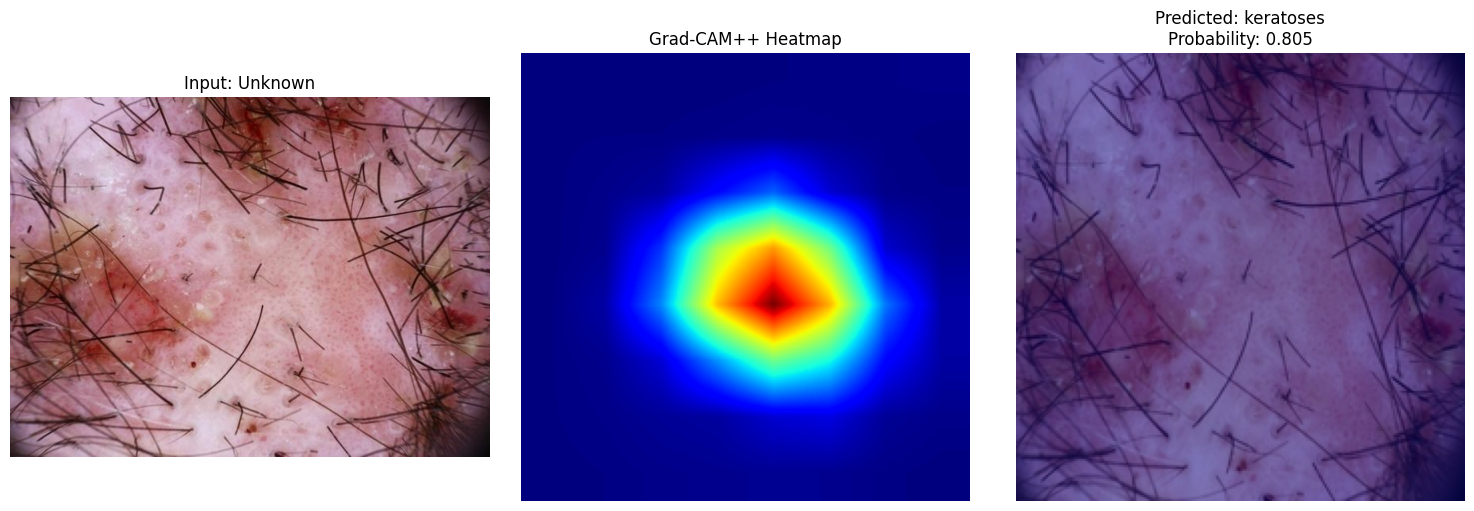

Grad-CAM++ overlay saved to: /content/drive/MyDrive/VisionMamba_InceptionV3_Swin_Ensemble/gradcampp_sample_50.png

Sending original image and Grad-CAM++ overlay to Gemini (gemini-2.5-flash)...
Could not use gemini-2.5-flash: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).', 'status': 'NOT_FOUND'}}
Waiting before trying alternative model...

Sending original image and Grad-CAM++ overlay to Gemini (gemini-1.5-flash)...
Could not use gemini-1.5-flash: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'models/gemini-1.5-flash is not found for API version v1beta, or is not supported for generateContent. Call ModelService.ListModels to see the list of available models and their supported methods.', 'status': 'NOT_FOUND'}}
Wait

In [27]:

# ================================================================
# Grad-CAM++ + Gemini API
# Vision Mamba + InceptionV3 + Swin Adaptive Fusion
# ================================================================

!pip -q install google-genai

import os
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from PIL import Image
from google import genai
from google.colab import userdata

# ------------------------------------------------
# 1. Select a test image
# ------------------------------------------------
SAMPLE_INDEX = 50

assert len(all_paths) > SAMPLE_INDEX, "Invalid SAMPLE_INDEX"

img_path = str(all_paths[SAMPLE_INDEX])
original_image = Image.open(img_path).convert("RGB")

x_v = VIM_TF(original_image).unsqueeze(0).to(DEVICE)
x_i = INCEPTION_TF(original_image).unsqueeze(0).to(DEVICE)
x_s = SWIN_TF(original_image).unsqueeze(0).to(DEVICE)

# ------------------------------------------------
# 2. Get the actual label from the dataset folder
# ------------------------------------------------
class_names = [str(c) for c in CLASSES]

path_parts = [
    part.lower().replace("_", " ").replace("-", " ").strip()
    for part in os.path.normpath(img_path).split(os.sep)
]

true_class = "Unknown"
for class_name in class_names:
    normalized = class_name.lower().replace("_", " ").replace("-", " ").strip()
    if normalized in path_parts:
        true_class = class_name
        break

# Display-friendly names for common skin-lesion classes
def display_class(name):
    normalized = str(name).lower().replace("_", " ").replace("-", " ").strip()

    aliases = {
        "bcc": "BCC (Basal Cell Carcinoma)",
        "basal cell carcinoma": "BCC (Basal Cell Carcinoma)",
        "scc": "SCC (Squamous Cell Carcinoma)",
        "squamous cell carcinoma": "SCC (Squamous Cell Carcinoma)",
        "melanoma": "Melanoma",
        "mel": "Melanoma",
        "nv": "Melanocytic Nevus",
        "nevus": "Melanocytic Nevus",
        "bkl": "Benign Keratosis",
        "akiec": "Actinic Keratosis / Intraepithelial Carcinoma",
        "vasc": "Vascular Lesion",
        "df": "Dermatofibroma",
    }

    return aliases.get(normalized, str(name))

true_class_display = display_class(true_class)

# ------------------------------------------------
# 3. Differentiable adaptive-fusion model
# ------------------------------------------------
class FusionForGradCAM(nn.Module):
    def __init__(self, vim, inception, swin, fusion):
        super().__init__()
        self.vim = vim
        self.inception = inception
        self.swin = swin
        self.fusion = fusion

    def forward(self, x_v, x_i, x_s):
        v = self.vim(x_v)
        if isinstance(v, (tuple, list)):
            v = v[0]
        if hasattr(v, "logits"):
            v = v.logits

        inc = self.inception(x_i)
        if hasattr(inc, "logits"):
            inc = inc.logits
        elif isinstance(inc, (tuple, list)):
            inc = inc[0]

        s = self.swin(x_s)
        if isinstance(s, (tuple, list)):
            s = s[0]
        if hasattr(s, "logits"):
            s = s.logits

        pv = F.softmax(v.float(), dim=1)
        pi = F.softmax(inc.float(), dim=1)
        ps = F.softmax(s.float(), dim=1)

        fused_result = self.fusion(pv, pi, ps)
        fused_prob = (
            fused_result[0]
            if isinstance(fused_result, (tuple, list))
            else fused_result
        )

        return fused_prob


ig_model = FusionForGradCAM(
    vim_model,
    inception_model,
    swin_model,
    fusion_model
).to(DEVICE)

ig_model.eval()

# ------------------------------------------------
# 4. Locate InceptionV3's final convolutional feature layer
# ------------------------------------------------
named_modules = list(inception_model.named_modules())

target_layer = None

for name, module in named_modules:
    if name.endswith("Mixed_7c"):
        target_layer = module
        break

if target_layer is None:
    conv_layers = [
        module for _, module in named_modules
        if isinstance(module, nn.Conv2d)
    ]
    if not conv_layers:
        raise RuntimeError(
            "No Conv2d layer found in inception_model. "
            "Select a convolutional feature layer manually."
        )
    target_layer = conv_layers[-1]

print("Grad-CAM++ layer:", target_layer.__class__.__name__)

# ------------------------------------------------
# 5. Capture feature maps using a forward hook
# ------------------------------------------------
captured = {}

def save_activation(module, inputs, output):
    if isinstance(output, (tuple, list)):
        output = output[0]
    captured["activation"] = output

hook_handle = target_layer.register_forward_hook(save_activation)

# ------------------------------------------------
# 6. Ensemble prediction + Grad-CAM++ calculation
# ------------------------------------------------
try:
    ig_model.zero_grad(set_to_none=True)

    with torch.enable_grad():
        fused_prob = ig_model(x_v, x_i, x_s)

        pred_idx = int(fused_prob.detach().argmax(dim=1).item())
        predicted_class = CLASSES[pred_idx]
        confidence = float(fused_prob[0, pred_idx].detach().item())

        if "activation" not in captured:
            raise RuntimeError("Inception feature maps were not captured.")

        activations = captured["activation"]

        # Gradient of the ensemble's predicted-class probability
        score = fused_prob[0, pred_idx]

        gradients = torch.autograd.grad(
            outputs=score,
            inputs=activations,
            create_graph=True,
            retain_graph=True
        )[0]

        # Grad-CAM++ alpha weights
        grad_2 = gradients.pow(2)
        grad_3 = gradients.pow(3)

        activation_sum = activations.sum(
            dim=(2, 3), keepdim=True
        )

        denominator = (
            2.0 * grad_2
            + activation_sum * grad_3
        )

        alpha = grad_2 / (denominator + 1e-8)

        positive_gradients = F.relu(gradients)

        weights = (
            alpha * positive_gradients
        ).sum(dim=(2, 3), keepdim=True)

        cam = (
            weights * activations
        ).sum(dim=1, keepdim=True)

        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().float().cpu().numpy()

finally:
    hook_handle.remove()

# Normalize the heatmap to [0, 1]
cam = np.maximum(cam, 0)
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

print("\n========== CLASSIFICATION RESULT ==========")
print("Image path:", img_path)
print("Actual dataset class:", true_class_display)
print("Predicted class:", display_class(predicted_class))
print(f"Ensemble class probability: {confidence:.4f}")

# ------------------------------------------------
# 7. Create and save Grad-CAM++ overlay
# ------------------------------------------------
original_224 = original_image.resize((224, 224))
original_array = np.asarray(original_224).astype(np.float32) / 255.0

# Use colormaps interface to prevent warning
heat_rgb = plt.colormaps.get_cmap("jet")(cam)[..., :3]

overlay_array = np.clip(
    0.55 * original_array + 0.45 * heat_rgb,
    0,
    1
)

overlay_image = Image.fromarray(
    (overlay_array * 255).astype(np.uint8)
)

OUT_DIR = (
    "/content/drive/MyDrive/"
    "VisionMamba_InceptionV3_Swin_Ensemble"
)
os.makedirs(OUT_DIR, exist_ok=True)

CAM_OVERLAY_PATH = os.path.join(
    OUT_DIR, f"gradcampp_sample_{SAMPLE_INDEX}.png"
)
overlay_image.save(CAM_OVERLAY_PATH)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Input: {true_class_display}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM++ Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay_image)
plt.title(
    f"Predicted: {display_class(predicted_class)}\n"
    f"Probability: {confidence:.3f}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

print("Grad-CAM++ overlay saved to:", CAM_OVERLAY_PATH)

# ------------------------------------------------
# 8. Connect to Gemini API
# ------------------------------------------------
api_key = userdata.get("GEMINI_API_KEY")

if not api_key:
    raise ValueError(
        "GEMINI_API_KEY missing. Add it in Colab Secrets "
        "and enable Notebook access."
    )

client = genai.Client(api_key=api_key)

# ------------------------------------------------
# 9. Send original image + Grad-CAM++ overlay to Gemini with fallback/retry
# ------------------------------------------------
prompt = f"""
Analyze the attached skin-lesion image and Grad-CAM++ overlay
for educational and research purposes only.

Actual dataset label: {true_class_display}
Ensemble model predicted label: {display_class(predicted_class)}
Predicted-class probability: {confidence:.4f}

Image 1: Original skin-lesion image.
Image 2: Grad-CAM++ overlay from the InceptionV3 branch of a
Vision Mamba + InceptionV3 + Swin adaptive-fusion ensemble.

The heatmap shows regions influencing the selected model output.
It does not confirm cancer, diagnosis, severity, or lesion boundaries.

Please provide:
1. A brief explanation of the model's predicted class.
2. Visible image characteristics that can reasonably be described.
3. What the highlighted regions may indicate about model attention.
4. General educational information about the predicted class.
5. General advice on appropriate professional evaluation.

Clearly distinguish the dataset label from the model prediction.
Do not claim the image or heatmap confirms a diagnosis.
Do not prescribe medicines, dosages, or personal treatment.
Recommend assessment by a qualified dermatologist.
Use clear, concise English.
"""

# Retry with production-supported models under Google GenAI SDK (v1)
models_to_try = ["gemini-2.5-flash", "gemini-1.5-flash"]
response = None

for model_name in models_to_try:
    print(f"\nSending original image and Grad-CAM++ overlay to Gemini ({model_name})...")
    try:
        response = client.models.generate_content(
            model=model_name,
            contents=[
                prompt,
                original_image,
                overlay_image,
            ],
        )
        break
    except Exception as e:
        print(f"Could not use {model_name}: {e}")
        print("Waiting before trying alternative model...")
        time.sleep(3)

# ------------------------------------------------
# 10. Display final result
# ------------------------------------------------
print("\n" + "=" * 65)
print("SKIN LESION CLASSIFICATION + GRAD-CAM++ + GEMINI")
print("=" * 65)

print("Actual dataset label:", true_class_display)
print("Predicted class:", display_class(predicted_class))
print(f"Model probability: {confidence:.4f}")

print("\nGemini-generated explanation:\n")

if response and response.text:
    print(response.text)
else:
    print("Gemini returned no text. Check the API response and quota.")

print("\nOriginal image:", img_path)
print("Grad-CAM++ overlay:", CAM_OVERLAY_PATH)

print(
    "\nMedical note: This AI result is not a confirmed diagnosis. "
    "Consult a qualified dermatologist for assessment."
)


In [33]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/skin dataset/MILK10k_Split"
IMAGE_ID = "ISIC_0680433"

found = False

for root, dirs, files in os.walk("/content/drive/MyDrive/skin dataset"):
    for file in files:
        if not file.lower().endswith(".csv"):
            continue

        path = os.path.join(root, file)

        try:
            df = pd.read_csv(path)
            cols = {c.lower().strip(): c for c in df.columns}

            if "isic_id" in cols and "diagnosis_full" in cols:
                match = df[
                    df[cols["isic_id"]].astype(str).str.strip()
                    == IMAGE_ID
                ]

                if not match.empty:
                    print("CSV file:", path)
                    print("\nMatching image diagnosis:")
                    print(match[[cols["isic_id"],
                                 cols["diagnosis_full"]]].to_string(index=False))
                    found = True

        except Exception:
            pass

if not found:
    print("Matching CSV/diagnosis row not found.")

CSV file: /content/drive/MyDrive/skin dataset/MILK10k_Split/test/Supplement_modified.csv

Matching image diagnosis:
     isic_id                                  diagnosis_full
ISIC_0680433 Squamous cell carcinoma in situ, Bowens disease


In [18]:
# ================================================================
# 13. Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report, confusion_matrix
)

def metrics(y, p):
    return {
        "Accuracy": accuracy_score(y, p),
        "Balanced Accuracy": balanced_accuracy_score(y, p),
        "Macro Precision": precision_score(y, p, average="macro", zero_division=0),
        "Macro Recall": recall_score(y, p, average="macro", zero_division=0),
        "Macro F1": f1_score(y, p, average="macro", zero_division=0),
        "Weighted F1": f1_score(y, p, average="weighted", zero_division=0),
    }

rows=[]
for name,p in [
    ("Vision Mamba",vim_pred),
    ("InceptionV3",inc_pred),
    ("Swin Transformer",swin_pred),
    ("Attention Adaptive Ensemble",ens_pred),
]:
    rows.append({"Model":name, **metrics(y_true,p)})

results_df = pd.DataFrame(rows)
print(results_df.to_string(index=False, float_format=lambda x:f"{x:.4f}"))


                      Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
               Vision Mamba    0.6836             0.5285           0.6036        0.5285    0.5488       0.6733
                InceptionV3    0.7033             0.5346           0.6118        0.5346    0.5516       0.6768
           Swin Transformer    0.7261             0.5915           0.6373        0.5915    0.6078       0.7106
Attention Adaptive Ensemble    0.7261             0.5659           0.6479        0.5659    0.5911       0.7041


In [19]:
# ================================================================
# 14. Ensemble classification report + confusion matrix
# ================================================================
print("\n" + "="*80)
print("3-MODEL ENSEMBLE CLASSIFICATION REPORT")
print("="*80)
print(classification_report(
    y_true, ens_pred, target_names=CLASSES, digits=4, zero_division=0
))

cm = confusion_matrix(y_true, ens_pred, labels=list(range(NUM_CLASSES)))
cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
print("Confusion matrix:")
print(cm_df)



3-MODEL ENSEMBLE CLASSIFICATION REPORT
              precision    recall  f1-score   support

    melanoma     0.5921    0.5357    0.5625        84
       nevus     0.7881    0.6761    0.7278       176
         bcc     0.7765    0.9585    0.8579       482
         scc     0.6042    0.2843    0.3867       102
   keratoses     0.4787    0.3750    0.4206       120

    accuracy                         0.7261       964
   macro avg     0.6479    0.5659    0.5911       964
weighted avg     0.7072    0.7261    0.7041       964

Confusion matrix:
           melanoma  nevus  bcc  scc  keratoses
melanoma         45     21    8    0         10
nevus            26    119   21    1          9
bcc               1      2  462    9          8
scc               0      1   50   29         22
keratoses         4      8   54    9         45


In [20]:
# ================================================================
# 15. Save ensemble predictions, probabilities and attention weights
# ================================================================
OUT_DIR = "/content/drive/MyDrive/VisionMamba_InceptionV3_Swin_Ensemble"
os.makedirs(OUT_DIR, exist_ok=True)

out_df = pd.DataFrame({
    "path": all_paths,
    "true_label": y_true,
    "true_class": [CLASSES[i] for i in y_true],
    "vim_prediction": vim_pred,
    "vim_class": [CLASSES[i] for i in vim_pred],
    "inception_prediction": inc_pred,
    "inception_class": [CLASSES[i] for i in inc_pred],
    "swin_prediction": swin_pred,
    "swin_class": [CLASSES[i] for i in swin_pred],
    "attention_vim_weight": attention_weights[:, 0],
    "attention_inception_weight": attention_weights[:, 1],
    "attention_swin_weight": attention_weights[:, 2],
    "ensemble_prediction": ens_pred,
    "ensemble_class": [CLASSES[i] for i in ens_pred],
})

out_df.to_csv(os.path.join(OUT_DIR, "attention_adaptive_ensemble_test_predictions.csv"), index=False)
np.save(os.path.join(OUT_DIR, "vision_mamba_probabilities.npy"), vim_prob)
np.save(os.path.join(OUT_DIR, "inceptionv3_probabilities.npy"), inc_prob)
np.save(os.path.join(OUT_DIR, "swin_probabilities.npy"), swin_prob)
np.save(os.path.join(OUT_DIR, "attention_adaptive_ensemble_probabilities.npy"), ens_prob)
np.save(os.path.join(OUT_DIR, "attention_adaptive_weights.npy"), attention_weights)
results_df.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index=False)
cm_df.to_csv(os.path.join(OUT_DIR, "attention_adaptive_ensemble_confusion_matrix.csv"))

print("Saved all ensemble outputs to:", OUT_DIR)
print("Attention fusion checkpoint:", FUSION_CHECKPOINT)


Saved all ensemble outputs to: /content/drive/MyDrive/VisionMamba_InceptionV3_Swin_Ensemble
Attention fusion checkpoint: /content/drive/MyDrive/VisionMamba_InceptionV3_Swin_Ensemble/attention_adaptive_fusion_best.pth


In [21]:
# ================================================================
# 16. Final summary
# ================================================================
ens_m = metrics(y_true, ens_pred)
print("\nFINAL ATTENTION-BASED ADAPTIVE ENSEMBLE")
print("-"*60)
for k,v in ens_m.items():
    print(f"{k:<20}: {v:.4f}")
print("-"*60)
print("Architecture: Vision Mamba + InceptionV3 + Swin Transformer")
print("Fusion: Attention-Based Adaptive Fusion")
print("Fusion learns sample-specific weights for the three model probabilities.")
print("Classes:", CLASSES)
print("\nAverage learned weights:")
print(f"Vision Mamba : {attention_weights[:,0].mean():.4f}")
print(f"InceptionV3  : {attention_weights[:,1].mean():.4f}")
print(f"Swin         : {attention_weights[:,2].mean():.4f}")
print("\nOutputs:", OUT_DIR)



FINAL ATTENTION-BASED ADAPTIVE ENSEMBLE
------------------------------------------------------------
Accuracy            : 0.7261
Balanced Accuracy   : 0.5659
Macro Precision     : 0.6479
Macro Recall        : 0.5659
Macro F1            : 0.5911
Weighted F1         : 0.7041
------------------------------------------------------------
Architecture: Vision Mamba + InceptionV3 + Swin Transformer
Fusion: Attention-Based Adaptive Fusion
Fusion learns sample-specific weights for the three model probabilities.
Classes: ['melanoma', 'nevus', 'bcc', 'scc', 'keratoses']

Average learned weights:
Vision Mamba : 0.3905
InceptionV3  : 0.3035
Swin         : 0.3061

Outputs: /content/drive/MyDrive/VisionMamba_InceptionV3_Swin_Ensemble
